In [ ]:
import jax
import jax.numpy as jnp
import jax.scipy as jsp

# **Drift-diffusion model of reaction times** ($rt$ )


**Wiener process with drift:**

$\delta x = v\,\delta t + \xi(t)\,\delta t \qquad\mathrm{where}\quad \xi(t)\sim \mathcal{N}(0,1) $

---

**first-passage time:** 

from Navarro & Fuss, 2009: <br> 
approximation of the first-passage time density of a Wiener process with two absorbing bounds ($0$ and $a$) and a biased starting point ( $w\cdot a$, where $w\in(0,1)$ ) at the lower bound:

$f(t|v,a,w) = \frac{1}{a^2} \exp(-vaw-\frac{v^2t}{2})f(\frac{t}{a^2}|0,1,w)$

* short-time approximation (for odd k):<br>
  $f(t|0,1,w) = \frac{1}{\sqrt{2\pi t^3}}  \sum_{k=-(K_s-1)/2}^{(K_s-1)/2} (w+2k) \exp\big(-\frac{(w+2k)^2}{2t}\big)$
  
* long-time approximation:<br>
  $f(t|0,1,w) = \pi \sum_{k=1}^{K_l} k \exp\big(-\frac{k^2 \pi^2 t}{2}\big)\sin(k\pi w)$

(For the upper bound change $v$ to $-v$ and $w$ to $1-w$.

---
**cumulative distributions** 

from Blurton, Kesselmeier, Gondan, 2012

* short-time approximation (for odd k):<br>
  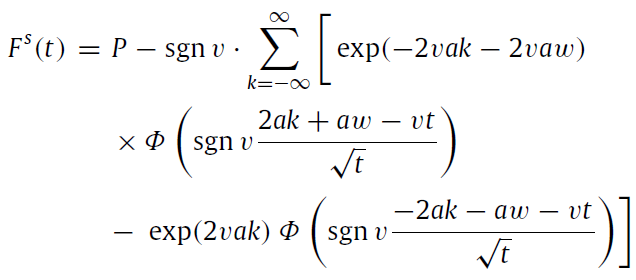
  
  
* long-time approximation:<br>
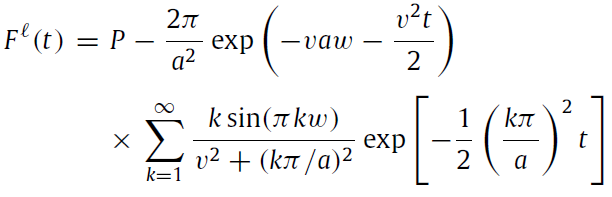

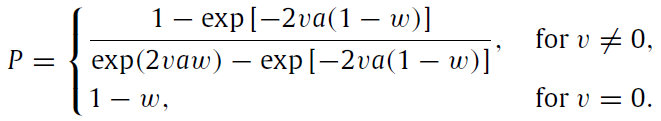

<!-- if $v \neq 0$:
$P = 1-w$

else:
$P = \frac{1-\exp(-2va(1-w))}{\exp(2vaw)-\exp(-2va(1-w))}$ -->

---

**choosing the right approximation:**

* short-time expansion error:<br>
$\epsilon_s^k(t) = \frac{1}{\sqrt{8\pi t}}\exp\big(-\frac{(k-2)^2}{2t}\big) \qquad \mathrm{valid\,when} \quad t < (k-1)^2$ 

* large-time expansion error bound:<br>
$\epsilon_l^k(t) = \frac{1}{\pi t}\exp\big(-\frac{k^2 \pi^2}{2} t \big) \qquad \mathrm{valid\,when} \quad t > \frac{1}{\pi^2 k^2}$ 

our method: first fixing the $k$ and for each $t$ use the approximation that leads to smaller error

---

**decision time:**<br>
$rt_D \sim f(t|v,a,w)$

In [ ]:
def jax_wfpt_aux(v,w,a,t,tt,use_small_t,k):
    """
    Evaluate the lower-boundary Wiener first-passage-time (wfpt) density.
    Auxiliary function used by jax_wfpt.

    Parameters
    ----------
    v : drift rate.
    w : relative starting position between the boundaries (0 < w < 1).
    a : boundary separation (a > 0); the diffusion scale is fixed to one.
    t : positive decision-time grid, shaped (n_times, 1).
    tt : rescaled time, t / a**2.
    use_small_t : Boolean mask selecting the small-time series.
    k : number of retained terms in each series; must be odd.

    Returns
    -------
    Density values with shape (n_times, 1).
    """

    pi = jnp.pi

    # Series indices: ks for the small-time expansion, kl for the
    # large-time expansion. For k=21, these are -10,...,10 and 1,...,21.
    # Each has shape (1, k), broadcasting against the time column.
    ks = jnp.arange(-(k-1)/2,(k-1)/2+1,1,dtype='int32').reshape(1,-1)      # +1 is due to numpy arange convention
    kl = jnp.arange(1,k+1,1,dtype='int32').reshape(1,-1)                   # +1 is due to numpy arange convention

    # ps and pl are the small-time and large-time approximations to
    # the zero-drift density on the rescaled time axis.
    # Sum over series terms, retaining the time column.
    ps = jnp.sum((w+2*ks)*jnp.exp(-((w+2*ks)**2)/(2*tt)), axis=1, keepdims=1) / jnp.sqrt(2*pi* tt**3)
    pl = jnp.sum(kl*jnp.exp(-(kl**2 * pi**2)*tt/2) * jnp.sin(kl*pi*w), axis=1, keepdims=1)*pi
    
    # Select the expansion using the error-based mask from jax_wfpt.
    p  = jnp.where(use_small_t, ps, pl)

    # Apply the drift correction and the 1/a**2 time-rescaling factor.
    p  = jnp.exp( jnp.log(p) - (v*a*w + (v**2)*t/2) - 2*jnp.log(a) )

    return p



def jax_wfpt(v,w,a,grid_t,k):

    """
    Approximate decision-time bin masses for both response boundaries.

    Parameters
    ----------
    # v:  drift rate
    # w:  relative starting point
    # a:  bound separation
    # grid_t: rt grid
    # k:  number of terms in the series expansion (must be odd)

    Returns
    -------
    Array with shape (n_times, 2):
    column 0 represents the lower boundary, column 1 the upper boundary.
    Each column sums to its boundary's approximate cumulative hitting
    probability at grid_t[-1]. The combined sum can therefore be below one.
    """
    
    pi = jnp.pi

    # t is decision time; tt is time rescaled to unit boundary separation.
    t  = grid_t
    tt = t/(a**2)

    # log_eps_s and log_eps_l are log truncation-error bounds for the
    # small-time and large-time expansions, respectively. (log space for numerical stability)
    log_eps_s = -jnp.log(jnp.sqrt(8*pi*tt)) - (k-2)**2/(2*tt)       # small t expansion error upper bound
    log_eps_l = -jnp.log(pi*tt)             - tt*(k**2 * pi**2)/2   # large t expansion error upper bound
    use_small_t = jnp.where( ( (log_eps_s <= log_eps_l) & (tt < (k-1)**2) ) | (tt < 1.0/(pi**2 * k**2)) , True, False)    
    
    # RT distribution for the lower and upper bound:
    p_W = jnp.concatenate( (jax_wfpt_aux(v,w,a,t,tt,use_small_t,k),  jax_wfpt_aux(-v,1-w,a,t,tt,use_small_t,k) ),axis=1)
    p_W = p_W/jnp.sum(p_W,axis=0,keepdims=True)
    p_W = p_W * jnp.concatenate( (jax_wfpt_aux_cum(v,w,a,t,k),  jax_wfpt_aux_cum(-v,1-w,a,t,k) ),axis=1) #  normalizing with the cumulative densities
    
    return p_W

def jax_wfpt_aux_cum(v,w,a,t,k):
    """
    Approximate the lower-boundary cumulative probability at t[-1].

    Parameters
    ----------
    # v:  drift rate
    # w:  relative starting point
    # a:  bound separation
    # grid_t: rt grid
    # k:  number of terms in the series expansion (must be odd)
    
    """
    
    pi = jnp.pi
    
    # Positive integer indices for the k retained large-time series terms.
    kl = jnp.arange(1,k+1,1,dtype='int32').reshape(1,-1)                   # +1 is due to numpy arange convention

    # P is the eventual lower-boundary hitting probability, with no
    # time limit. For near-zero drift, its limiting value is 1-w.
    P = jnp.where(jnp.abs(v*a) > 10**-5, (1-jnp.exp(-2*v*a*(1-w)))/(jnp.exp(2*v*a*w)-jnp.exp(-2*v*a*(1-w))), 1-w)

    # F_aux is the series component of the probability of hitting the
    # lower boundary after t[-1]. The prefactor is applied below.
    F_aux = jnp.sum( kl*jnp.sin(pi*kl*w)/(v**2 + (kl*pi/a)**2) *jnp.exp(-t[-1]/2*(kl*pi/a)**2) , axis=1, keepdims=1)
    F = P - 2*pi/(a**2)* jnp.exp( -(v*a*w + (v**2)*t[-1]/2) ) * F_aux
    
    return F

**additional noises:**

variable non decision time:<br>
$rt_0 \sim \mathrm{LogNorm}(\log(t_0),\sigma_{t_0})$

unifrom lapse:<br>
$rt_l \sim \mathrm{Unif}(t_{\min},t_{\max})$

---

**observed reaction time:**

$rt = \begin{cases}
rt_D + rt_0 & \text{  with probability $(1-l)$}\\
rt_l & \text{  with probability $l$}
\end{cases}$

In [ ]:
def jax_wfpt_noisy(v,w,a,t0,t0_lsig,l,grid_t,k):

    """
    Combine Wiener decision times, variable nondecision times, and lapses.

    Parameters
    ----------
    v : drift rate
    w : relative starting position 
    a : boundary separation 
    t0 : median of the lognormal nondecision-time distribution
    t0_lsig : standard deviation of log nondecision time
    l : lapse probability (0 <= l <= 1).
    grid_t : positive, uniformly spaced time grid, shape (n_times, 1).
    k : number of retained Wiener series terms; must be odd.

    Returns
    -------
    Array with shape (n_times, 2), containing approximate reaction-time
    bin masses for lower-boundary responses (column 0) and upper-boundary
    responses (column 1). Its total mass can be below one because times
    outside the retained window are excluded.

    """

    # Wiener pdf
    p_W = jax_wfpt(v,w,a,grid_t,k)

    # non-decision time pdf
    p_t0_noise = jsp.stats.norm.pdf(jnp.log(grid_t),jnp.log(t0),t0_lsig) / grid_t
    p_t0_noise = p_t0_noise/jnp.sum(p_t0_noise) * jax.scipy.stats.norm.cdf( jnp.log(grid_t[-1]),jnp.log(t0),t0_lsig )
    
    
    # Wiener + noisy non-decision time pdf
    p_aux = jnp.concatenate( ( jnp.convolve(p_t0_noise.reshape(-1),p_W[:,0].reshape(-1)).reshape(-1,1) , jnp.convolve(p_t0_noise.reshape(-1),p_W[:,1].reshape(-1)).reshape(-1,1) ), axis=1)
    p = p_aux[0:(grid_t.size),:]
    
    p = p/jnp.maximum(jnp.sum(p),1) # ensure that the integral of probability is not bigger then 1
    
    #Wiener + noisy non-decision time + lapse pdf
    p_lapse = grid_t*0+1
    p_lapse = p_lapse/sum(p_lapse)
    p = (1.0-l)*p + l*p_lapse/2

    return p 


**Example usage**

Computes and plots reaction-time distributions for responses A (lower boundary) and B (upper boundary), together with their choice proportions, using specified drift-diffusion model parameters (v,w,a,t0,t0_lsig,lapse).

Optional arguments:
- show_Wiener=True: overlays the decision-time distributions before adding nondecision time and lapses as dotted lines.
- show_mean_RT=True: adds vertical lines and annotations showing the full model’s mean reaction time for each response, conditional on the plotted time window.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb


def example_wfpt(show_mean_RT=False, show_Wiener=True):
    """Plot reaction-time distributions and the corresponding choice shares."""

    grid_t = jnp.linspace(0.01, 3.0, 300).reshape(-1, 1)



    grid_t = jnp.linspace(0.01, 3.0, 300).reshape(-1, 1)
    v, w, a = 1.0, 0.4, 1.5
    t0, t0_lsig, lapse = 0.3, 0.2, 0.02
    k = 21

    p_before = np.asarray(jax_wfpt(v, w, a, grid_t, k))
    p_after = np.asarray(
        jax_wfpt_noisy(v, w, a, t0, t0_lsig, lapse, grid_t, k)
    )

    # Choice percentages conditional on the retained reaction-time window.
    choice_mass = p_after.sum(axis=0)
    percentages = 100.0 * choice_mass / choice_mass.sum()
    pct_a, pct_b = map(float, percentages)

    colors = ("tab:blue", "tab:orange")
    fig, (ax_rt, ax_choice) = plt.subplots(1, 2, figsize=(8, 4),
        gridspec_kw={"width_ratios": [5, 1]},
        layout="constrained",
    )

    if show_Wiener:
        ax_rt.plot(grid_t[:, 0], p_before[:, 0], color=tuple(c + 0.5 * (1 - c) for c in to_rgb(colors[0])), label="resp. A (Wiener only)", linestyle=':')
        ax_rt.plot(grid_t[:, 0], p_before[:, 1], color=tuple(c + 0.5 * (1 - c) for c in to_rgb(colors[1])), label="resp. B (Wiener only)", linestyle=':')
    ax_rt.plot(grid_t[:, 0], p_after[:, 0], color=colors[0], label="resp. A (full model)")
    ax_rt.plot(grid_t[:, 0], p_after[:, 1], color=colors[1], label="resp. B (full model)")
    ax_rt.set_xlabel("reaction time (s)")
    ax_rt.set_ylabel("probability density")
    ax_rt.legend()

    # Mean RT for each response, conditional on the retained time window.
    if show_mean_RT:
        mean_rt = (np.asarray(grid_t) * p_after).sum(axis=0) / choice_mass
    
        for i, mean in enumerate(mean_rt):
            ax_rt.axvline(mean, color=colors[i], linewidth=1, alpha=0.7)
            ax_rt.annotate(
                f"mean RT = {mean:.2f} s",
                xy=(mean, 0.55 - 0.15 * i),
                xycoords=ax_rt.get_xaxis_transform(),
                xytext=(5, 0),
                textcoords="offset points",
                color=colors[i],
                rotation=90,
                va="center",
            )


    # A single stacked bar summarizes the two choice percentages.
    ax_choice.bar(0, pct_a, width=0.6, color=colors[0])
    ax_choice.bar(0, pct_b, bottom=pct_a, width=0.6, color=colors[1])

    ax_choice.text(
        0, pct_a / 2, f"A\n{pct_a:.1f}%",
        ha="center", va="center", color="white",
    )
    ax_choice.text(
        0, pct_a + pct_b / 2, f"B\n{pct_b:.1f}%",
        ha="center", va="center", color="white",
    )
    ax_choice.set_ylim(0, 100)
    ax_choice.set_xlim(-0.6, 0.6)
    ax_choice.set_axis_off()
    ax_choice.set_title("proportion\nof choices", loc="center")


    plt.show()
    return grid_t, p_after


grid_t, p = example_wfpt()
